| TESTE BERT LARGE |
Métricas medidas com SPAN e TOKEN com 10 épocas e 1 rodada no Collab.


Trainer padrão |
Sem save_strategy |
Eval_strategy e logging_strategy=”epoch” |
Learning_rate=2e-5 |
Gráfico de Aprendizagem e Curva Loss

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import os
caminho = '/content/drive/MyDrive/Colab Notebooks'
os.chdir(caminho)

In [21]:
# Update e instalação dos pacotes e dependências usados

!pip install -q transformers datasets evaluate seqeval accelerate
!pip install matplotlib

In [22]:
import torch
device = torch.device('cuda')
print(f"Usando dispositivo: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"🎮 GPU detectada: {gpu_name}")
    print(f"💾 VRAM Total: {vram_gb:.2f} GB")
else:
    print("Nenhuma GPU com suporte CUDA encontrada.")

Usando dispositivo: cuda
PyTorch version: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8
🎮 GPU detectada: NVIDIA L4
💾 VRAM Total: 23.66 GB


In [23]:
# Importações necessárias

import pandas as pd
import csv
import re
import torch
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Dict, Optional
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification,
    EarlyStoppingCallback)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support, accuracy_score

import os
import gc
import shutil
from datasets import disable_caching

from datasets import concatenate_datasets

from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

import evaluate
metric = evaluate.load("seqeval")
from seqeval.metrics import precision_score as seqeval_precision, recall_score as seqeval_recall


In [24]:
# Definição dos rótulos BIO
lista_rotulos = ["O", "B-WRONG", "I-WRONG"]
label_to_id = {label: i for i, label in enumerate(lista_rotulos)}
id_to_label = {i: label for i, label in enumerate(lista_rotulos)}

In [25]:
# Lê arquivo CONLL (TSV)

def ler_conll(
    path: str,
    *,
    ignore_header_regex: str = r"^\s*Sentença\s+Original\s+N[°º]\s*\d+",
    allow_space_in_token: bool = False,
    strict_two_columns: bool = False,
    verbose: bool = True,
) -> Tuple[List[List[str]], List[List[str]]]:
    header_pat = re.compile(ignore_header_regex, flags=re.IGNORECASE)
    tokens_per_sent, tags_per_sent = [], []
    cur_tokens, cur_tags = [], []

    def flush_sentence():
        nonlocal cur_tokens, cur_tags
        if cur_tokens:
            tokens_per_sent.append(cur_tokens)
            tags_per_sent.append(cur_tags)
        cur_tokens, cur_tags = [], []

    with open(path, "r", encoding="utf-8") as f:
        for lineno, raw in enumerate(f, start=1):
            line = raw.rstrip("\n")

            # Ignora linhas de cabeçalho por sentença
            if header_pat.search(line):
                flush_sentence()
                continue

            # Delimitador de sentença
            if line.strip() == "":
                flush_sentence()
                continue

            # Tenta split por TAB primeiro, senão por espaço
            if "\t" in line:
                parts = line.split("\t")
            else:
                # Divide por qualquer espaço
                parts = line.strip().split()

            if strict_two_columns:
                if len(parts) != 2:
                    if verbose:
                        print(f"[AVISO] Linha {lineno} ignorada (esperado 2 colunas): {line}")
                    continue
                token, tag = parts[0], parts[1]
            else:
                if len(parts) < 2:
                    if verbose:
                        print(f"[AVISO] Linha {lineno} ignorada (colunas insuficientes): {line}")
                    continue
                if allow_space_in_token:
                    # Última coluna é tag; o resto é token (pode conter espaços/tabs)
                    *token_parts, tag = parts
                    token = " ".join(token_parts)
                else:
                    # Primeira é token, última é tag (se houver colunas no meio, descartamos/avisamos)
                    token, tag = parts[0], parts[-1]
                    if len(parts) > 2 and verbose:
                        print(f"[OBSERVAÇÃO] Linha {lineno} possuía colunas extras; usando 1ª como token e última como tag.")

            # Sanidade básica da tag
            if not tag or tag.isspace():
                if verbose:
                    print(f"[AVISO] Linha {lineno} com tag vazia; ignorada: {line}")
                continue

            cur_tokens.append(token)
            cur_tags.append(tag)

    # Última sentença (se não terminar com linha em branco)
    flush_sentence()

    return tokens_per_sent, tags_per_sent

In [26]:
# Mapeia Label2ID e ID2Label

def build_label_maps(tags_per_sent: List[List[str]]) -> Tuple[Dict[str, int], Dict[int, str]]:
    labels = set()
    for sent_tags in tags_per_sent:
        labels.update(sent_tags)

    labels = list(labels)

    if "O" in labels:
        labels.remove("O")
        labels = ["O"] + sorted(labels)
    else:
        labels = sorted(labels)

    label2id = {lab: i for i, lab in enumerate(labels)} # Converte texto em número ['O': 0, 'B-WRONG': 1, 'I-WRONG': 2]
    id2label = {i: lab for lab, i in label2id.items()} # Converte número em texto [0: 'O', 1: 'B-WRONG', 2: 'I-WRONG']
    return label2id, id2label

In [27]:
# Constrói um dataset Hugging Face com colunas de tokens (List[str]) e ner_tags (List[int]).

def make_hf_dataset_from_tokens(
    tokens_per_sent: List[List[str]],
    tags_per_sent: List[List[str]],
    label2id: Optional[Dict[str, int]] = None,
) -> Tuple[Dataset, Dict[str, int]]:

    # Verifica se as sentenças de tokens e as sentenças de tags são equivalentes (mesmo número)
    assert len(tokens_per_sent) == len(tags_per_sent), "tokens e tags desalinhados"

    # Associa Label2ID ao mapeamento das tags feito anteriormente
    if label2id is None:
        label2id, _ = build_label_maps(tags_per_sent)

    # Tags desconhecidas serão associadas à tag O
    O_ID = label2id.get("O", 0)

    # Mapeamento com tratamento de erro
    encoded_tags = []
    for tags in tags_per_sent:
        sentence_tags = []
        for tag in tags:
            sentence_tags.append(label2id.get(tag, O_ID)) # Verifica se tag está mapeada ou se uso o ID 0
        encoded_tags.append(sentence_tags)

    ds = Dataset.from_dict({"tokens": tokens_per_sent, "ner_tags": encoded_tags})
    return ds, label2id

In [28]:
# Função para equiparar lista de labels com lista de tokens

def tokenize_and_align_labels(batch, tokenizer, label_all_subtokens: bool = False):
    tokenized = tokenizer(
        batch["tokens"],
        truncation=True,
        is_split_into_words=True,
    )

    all_labels = []
    for i, word_labels in enumerate(batch["ner_tags"]):
        # Mapeia o subtoken com a palavra original
        word_ids = tokenized.word_ids(batch_index=i)
        previous_word_id = None
        label_ids = []

        for word_id in word_ids:
            if word_id is None:
                # Caractere especial é ignorado
                label_ids.append(-100)
            elif word_id != previous_word_id:
                # Primeiro pedaço da palavra recebe tag original
                label_ids.append(word_labels[word_id])
            else:
                # Sub-token da mesma palavra (word) é alinhado à label original
                label_ids.append(word_labels[word_id] if label_all_subtokens else -100)
            previous_word_id = word_id

        all_labels.append(label_ids)

    tokenized["labels"] = all_labels
    return tokenized


In [29]:
# Função que retorna o objeto DatasetDict para o treinamento do modelo a partir das funções anteriores.

def load_custom_conll_dataset(
    files: Dict[str, str] | str,
    *,
    fixed_label2id: Optional[Dict[str, int]] = None,
    allow_space_in_token: bool = False,
    strict_two_columns: bool = False,
    verbose: bool = True,
) -> Tuple[DatasetDict, Dict[str, int], Dict[int, str]]:

    if isinstance(files, str):
        files = {"train": files}

    datasets_splits = {}
    cache_tokens = {}
    cache_tags = {}

    # Lê os splits
    for split_name, path in files.items():
        tokens_per_sent, tags_per_sent = ler_conll(
            path,
            allow_space_in_token=allow_space_in_token,
            strict_two_columns=strict_two_columns,
            verbose=verbose,
        )
        cache_tokens[split_name] = tokens_per_sent
        cache_tags[split_name] = tags_per_sent

    # Determinar o mapeamento de labels
    if fixed_label2id is not None:
        # Mapeamento fixo (BIO)
        accumulated_label2id = fixed_label2id
    else:
        # Remapeaia todas as tags caso não tenha labels definidas (fallback)
        all_tags = []
        for split_name in files.keys():
            all_tags.extend(cache_tags[split_name])
        accumulated_label2id, _ = build_label_maps(all_tags)

    accumulated_id2label = {i: lab for lab, i in accumulated_label2id.items()}

    # Constrói datasets usando o mapeamento (BIO)
    for split_name in files.keys():
        ds, _ = make_hf_dataset_from_tokens(
            cache_tokens[split_name],
            cache_tags[split_name],
            label2id=accumulated_label2id,
        )
        datasets_splits[split_name] = ds

    dset = DatasetDict(datasets_splits)
    return dset, accumulated_label2id, accumulated_id2label

In [30]:
# Carregamento do Dataset já com os labels BIO
path_treino = "train_bio.tsv"
path_teste = "test_bio.tsv"
path_validacao = "val_bio.tsv"

dataset, _, _ = load_custom_conll_dataset(
      files={"train": path_treino, "test": path_teste, "validation": path_validacao},
      fixed_label2id=label_to_id,
      allow_space_in_token=False,
      strict_two_columns=False,
      verbose=True,
)

# Unificação dos dados para que o sorteio 80/20 seja global a cada rodada
full_dataset = concatenate_datasets([
    dataset["train"],
    dataset["test"],
])

tokenizer = AutoTokenizer.from_pretrained("neuralmind/bert-large-portuguese-cased")

In [31]:
from collections import Counter

# check label distribution in the raw train split
tag_counts = Counter(
    id_to_label[t]
    for tags in dataset["train"]["ner_tags"]
    for t in tags
)
print(tag_counts)

total = sum(tag_counts.values())
for label, count in tag_counts.items():
    print(f"{label}: {count} ({count/total:.2%})")

Counter({'O': 345453, 'I-WRONG': 21586, 'B-WRONG': 11070})
O: 345453 (91.36%)
B-WRONG: 11070 (2.93%)
I-WRONG: 21586 (5.71%)


In [32]:
# Cria o data collator que faz padding dinâmico
data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,
    padding=True,
)

In [33]:
class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(
            weight=self.class_weights.to(logits.device),
            ignore_index=-100,
        )
        loss = loss_fct(logits.view(-1, logits.shape[-1]), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [34]:
# Threshold tuning on logits instead of raw argmax: punishes false positives more
def predict_with_threshold(logits, threshold=0.5):
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    o_id = label_to_id["O"]
    preds = np.argmax(logits, axis=-1)
    non_o_prob = 1 - probs[..., o_id]
    preds = np.where(non_o_prob >= threshold, preds, o_id)
    return preds

def span_f0_5_from_preds(preds, labels):
    true_seqs, pred_seqs = [], []
    for pred, label in zip(preds, labels):
        true_seq = [id_to_label[l] for p, l in zip(pred, label) if l != -100]
        pred_seq = [id_to_label[p] for p, l in zip(pred, label) if l != -100]
        true_seqs.append(true_seq)
        pred_seqs.append(pred_seq)
    p = seqeval_precision(true_seqs, pred_seqs, zero_division=0)
    r = seqeval_recall(true_seqs, pred_seqs, zero_division=0)
    f = 0.0 if p + r == 0 else (1.25 * p * r) / (0.25 * p + r)
    return p, r, f

def tune_threshold(trainer, eval_dataset, thresholds=np.arange(0.15, 0.95, 0.05)):
    raw_pred = trainer.predict(eval_dataset)
    logits, labels = raw_pred.predictions, raw_pred.label_ids
    best_t, best_p, best_r, best_f = 0.5, 0.0, 0.0, -1
    for t in thresholds:
        preds = predict_with_threshold(logits, t)
        p, r, f = span_f0_5_from_preds(preds, labels)
        if f > best_f:
            best_t, best_p, best_r, best_f = t, p, r, f
    return best_t, best_p, best_r, best_f

In [35]:
def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=2)

    # TOKEN-LEVEL

    # 1. Listas de predições e labels reais achatadas (token-level, dela)
    flat_predictions = []
    flat_labels = []

    for prediction, label in zip(predictions, labels):
        for p_id, l_id in zip(prediction, label):
            if l_id != -100:
                flat_predictions.append(p_id)
                flat_labels.append(l_id)

    # 2. Define as classes avaliadas (B-WRONG e I-WRONG)
    ids_interesse = [label_to_id[rotulo] for rotulo in lista_rotulos if rotulo != "O"]

    # 3. Calcula Precisão e Recall por token
    precision, recall, _, _ = precision_recall_fscore_support(
        flat_labels, flat_predictions,
        labels=ids_interesse, average='micro', zero_division=0
    )
    accuracy = accuracy_score(flat_labels, flat_predictions)

    # 4. F0.5 (token-level)
    if precision + recall == 0:
        f0_5 = 0.0
    else:
        f0_5 = (1 + 0.5**2) * (precision * recall) / ((0.5**2 * precision) + recall)

    # SPAN-LEVEL (SEQEVAL)
    true_seqs, pred_seqs = [], []
    for prediction, label in zip(predictions, labels):
        true_seq, pred_seq = [], []
        for p_id, l_id in zip(prediction, label):
            if l_id != -100:
                true_seq.append(id_to_label[l_id])
                pred_seq.append(id_to_label[p_id])
        true_seqs.append(true_seq)
        pred_seqs.append(pred_seq)

    span_precision = seqeval_precision(true_seqs, pred_seqs, zero_division=0)
    span_recall = seqeval_recall(true_seqs, pred_seqs, zero_division=0)
    if span_precision + span_recall == 0:
        span_f0_5 = 0.0
    else:
        span_f0_5 = (1 + 0.5**2) * (span_precision * span_recall) / ((0.5**2 * span_precision) + span_recall)

    return {
        "precision": precision,
        "recall": recall,
        "f0_5": f0_5,
        "accuracy": accuracy,
        "span_precision": span_precision,
        "span_recall": span_recall,
        "span_f0_5": span_f0_5,
    }

In [36]:
disable_caching()

# --- CONFIGURAÇÃO DO MODELO ---
nome_modelo = "neuralmind/bert-large-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(nome_modelo)

num_experimentos = 1
diretorio_local_temp = "temp_results"
caminho_salvamento_drive = "results/resultados_bertlarge.csv"

# Garantir que o diretório de destino existe
os.makedirs(os.path.dirname(caminho_salvamento_drive), exist_ok=True)

# Retomar os experimentos a partir do último checkpoint salvo
if os.path.exists(caminho_salvamento_drive):
    print("🔄 Arquivo parcial encontrado! Carregando progresso anterior...")
    df_carregado = pd.read_csv(caminho_salvamento_drive)

    if 'Precision_token' in df_carregado.columns:
        df_carregado = df_carregado[pd.to_numeric(df_carregado['Precision_token'], errors='coerce').notnull()]
        resultados_experimentos = df_carregado.to_dict(orient='records')
        rodada_inicial = len(resultados_experimentos)
        print(f"Resultados das primeiras {rodada_inicial} rodadas carregados. Retomando da rodada {rodada_inicial + 1}...")
    else:
        resultados_experimentos = []
        rodada_inicial = 0
else:
    print("\n*** ATENÇÃO: Nenhum checkpoint encontrado. Iniciando do zero... ***\n")
    resultados_experimentos = []
    rodada_inicial = 0

print(f"*** INÍCIO DO CICLO DE EXPERIMENTOS ({nome_modelo}) - Restam {num_experimentos - rodada_inicial} rodadas ***")
tokenized_validation = dataset["validation"].map(
    lambda batch: tokenize_and_align_labels(batch, tokenizer, label_all_subtokens=False),
    batched=True,
)

# Inicializa o rastreador da maior pontuação para o salvamento dos pesos no Drive
melhor_f05_geral = max([r.get('F0.5_span', 0.0) for r in resultados_experimentos], default=0.0)

for i in range(rodada_inicial, num_experimentos):
    current_seed = 100 + i

    # Split em memória RAM
    ds_split = full_dataset.shuffle(seed=current_seed).train_test_split(
        test_size=0.2,
        seed=current_seed,
        keep_in_memory=True
    )

    # Tokenização dinâmica em memória RAM
    tokenized_ds = ds_split.map(
        lambda batch: tokenize_and_align_labels(batch, tokenizer, label_all_subtokens=False),
        batched=True,
        load_from_cache_file=False,
        keep_in_memory=True
    )

    model = AutoModelForTokenClassification.from_pretrained(
        nome_modelo,
        num_labels=len(lista_rotulos),
        id2label=id_to_label,
        label2id=label_to_id
    )

    output_dir_atual = os.path.join(diretorio_local_temp, f"exp_{i+1}")
    use_bf16 = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8

    training_args = TrainingArguments(
        output_dir=output_dir_atual,
        learning_rate=2e-5,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=4,
        num_train_epochs=10,
        weight_decay=0.01,
        disable_tqdm=False,
        report_to=[],
        fp16=torch.cuda.is_available() and not use_bf16,
        bf16=use_bf16,
        eval_strategy="epoch",
        logging_strategy="epoch",
        save_strategy="no",
        load_best_model_at_end=False,
        metric_for_best_model="eval_span_f0_5",
        greater_is_better=True,
        warmup_ratio=0.1,
        logging_steps=100,
        save_total_limit=1
    )

    #class_weights = torch.tensor([1.0, 3.0, 2.0])

    #trainer = WeightedTrainer(
    #    model=model,
    #    args=training_args,
    #    train_dataset=tokenized_ds["train"],
    #    eval_dataset=tokenized_validation, # dataset de validacao para otimizacao de hiperparametros
    #    data_collator=data_collator,
    #    compute_metrics=compute_metrics,
    #    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)], # pegar o melhor modelo
    #    class_weights=class_weights,
    #)

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_ds["train"],
        eval_dataset=tokenized_validation,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    # Extrair e salvar os gráficos após treino
    log_history = trainer.state.log_history

    train_loss, eval_loss, eval_f0_5 = [], [], []
    epochs_train, epochs_eval = [], []

    for log in log_history:
        if 'loss' in log and 'epoch' in log:
            train_loss.append(log['loss'])
            epochs_train.append(log['epoch'])
        if 'eval_loss' in log and 'epoch' in log:
            eval_loss.append(log['eval_loss'])
            epochs_eval.append(log['epoch'])
        if 'eval_span_f0_5' in log and 'epoch' in log:
            eval_f0_5.append(log['eval_span_f0_5'])

    # 1. Salvar os logs brutos no Drive
    hist_df = pd.DataFrame(log_history)
    hist_df.to_csv(f"results/historico_log_exp_{i+1}.csv", index=False)

    # 2. Gerar e salvar a imagem da curva de aprendizado/loss
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_train, train_loss, label='Treino (Loss)', alpha=0.6)
    if eval_loss:
        plt.plot(epochs_eval, eval_loss, label='Validação (Loss)', marker='o', linewidth=2)
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.title(f'Curva de Loss - Experimento {i+1}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.subplot(1, 2, 2)
    if eval_f0_5:
        plt.plot(epochs_eval, eval_f0_5, label='F0.5 (Span) Validação', color='green', marker='o', linewidth=2)
    plt.xlabel('Épocas')
    plt.ylabel('F0.5 Score')
    plt.title(f'Curva de Aprendizagem - Experimento {i+1}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(f"results/curvas_exp_{i+1}.png", dpi=300)
    plt.close()

    # --- AVALIAÇÃO FINAL NO TESTE COM THRESHOLD TUNADO ---
    best_t, val_p, val_r, val_f = tune_threshold(trainer, tokenized_validation)

    test_pred = trainer.predict(tokenized_ds["test"])
    test_preds = predict_with_threshold(test_pred.predictions, best_t)

    # Métricas Span-level (Seqeval)
    test_p, test_r, test_f = span_f0_5_from_preds(test_preds, test_pred.label_ids)

    # Métricas Token-level (Recalculadas usando o mesmo Threshold Tunado)
    flat_preds = []
    flat_labels = []
    for pred, label in zip(test_preds, test_pred.label_ids):
        for p_id, l_id in zip(pred, label):
            if l_id != -100:
                flat_preds.append(p_id)
                flat_labels.append(l_id)

    ids_interesse = [label_to_id[rotulo] for rotulo in lista_rotulos if rotulo != "O"]
    prec_tok, rec_tok, _, _ = precision_recall_fscore_support(
        flat_labels, flat_preds, labels=ids_interesse, average='micro', zero_division=0
    )
    acc_tok = accuracy_score(flat_labels, flat_preds)
    f05_tok = (1.25 * prec_tok * rec_tok) / (0.25 * prec_tok + rec_tok) if (prec_tok + rec_tok) > 0 else 0.0

    # Salva os pesos no Drive se for o melhor resultado global até o momento
    if test_f > melhor_f05_geral:
        melhor_f05_geral = test_f
        caminho_melhor_modelo_drive = "results/melhor_modelo_bertlarge"
        trainer.save_model(caminho_melhor_modelo_drive)
        tokenizer.save_pretrained(caminho_melhor_modelo_drive)
        print(f"🏆 Novo recorde! Melhor modelo salvo em: '{caminho_melhor_modelo_drive}' (F0.5 Span: {test_f:.4f})")

    resultados_experimentos.append({
        'Precision_token': prec_tok,
        'Recall_token': rec_tok,
        'F0.5_token': f05_tok,
        'Accuracy': acc_tok,
        'Precision_span': test_p,
        'Recall_span': test_r,
        'F0.5_span': test_f,
        'Threshold': best_t,
    })

    # Salvamento parcial do CSV a cada rodada
    df_parcial = pd.DataFrame(resultados_experimentos)
    df_parcial.to_csv(caminho_salvamento_drive, index=False)

    print(f"✅ Rodada {i+1}/{num_experimentos} finalizada (Seed: {current_seed}) | F0_5 Span: {test_f:.4f} | Threshold: {best_t:.2f}")

    # Limpeza de memória VRAM e RAM
    del model
    del trainer
    del ds_split
    del tokenized_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if os.path.exists(output_dir_atual):
        shutil.rmtree(output_dir_atual)

if os.path.exists(diretorio_local_temp):
    shutil.rmtree(diretorio_local_temp)


*** ATENÇÃO: Nenhum checkpoint encontrado. Iniciando do zero... ***

*** INÍCIO DO CICLO DE EXPERIMENTOS (neuralmind/bert-large-portuguese-cased) - Restam 1 rodadas ***


Map:   0%|          | 0/1540 [00:00<?, ? examples/s]

Map:   0%|          | 0/14168 [00:00<?, ? examples/s]

Map:   0%|          | 0/3542 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.34GB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch,Training Loss,Validation Loss,Precision,Recall,F0 5,Accuracy,Span Precision,Span Recall,Span F0 5
1,1.380911,0.306187,0.607394,0.098656,0.299012,0.919692,0.446985,0.176374,0.342030
2,1.001901,0.310445,0.632000,0.090363,0.287430,0.919255,0.380353,0.123872,0.268970
3,0.729825,0.288932,0.479130,0.233057,0.395593,0.916588,0.295499,0.247744,0.284530
4,0.494298,0.357415,0.503840,0.187589,0.376795,0.917873,0.317839,0.207547,0.287304
5,0.338830,0.393886,0.520694,0.266228,0.437130,0.919789,0.351562,0.258409,0.327920
6,0.235122,0.486759,0.516409,0.238490,0.418801,0.919425,0.352878,0.271534,0.332931
7,0.167249,0.507713,0.507508,0.241636,0.415969,0.918746,0.350318,0.270714,0.330860
8,0.120096,0.571587,0.503712,0.252216,0.419960,0.918722,0.343404,0.279737,0.328453
9,0.091176,0.641820,0.524000,0.224764,0.413815,0.919740,0.365517,0.260870,0.338370
10,0.069953,0.662381,0.514178,0.233343,0.414424,0.919304,0.354874,0.265792,0.332581


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

🏆 Novo recorde! Melhor modelo salvo em: 'results/melhor_modelo_bertlarge' (F0.5 Span: 0.3544)
✅ Rodada 1/1 finalizada (Seed: 100) | F0_5 Span: 0.3544 | Threshold: 0.90


📊 RELATÓRIO ESTATÍSTICO GERAL (1 EXPERIMENTOS)
Precision_token   : 0.6240 (± nan)
Recall_token      : 0.1948 (± nan)
F0.5_token        : 0.4331 (± nan)
Accuracy          : 0.9177 (± nan)
Precision_span    : 0.4133 (± nan)
Recall_span       : 0.2257 (± nan)
F0.5_span         : 0.3544 (± nan)
Threshold         : 0.9000 (± nan)

✅ Relatório completo gravado com sucesso em: 'results/resultados_bertlarge_resumo.csv'


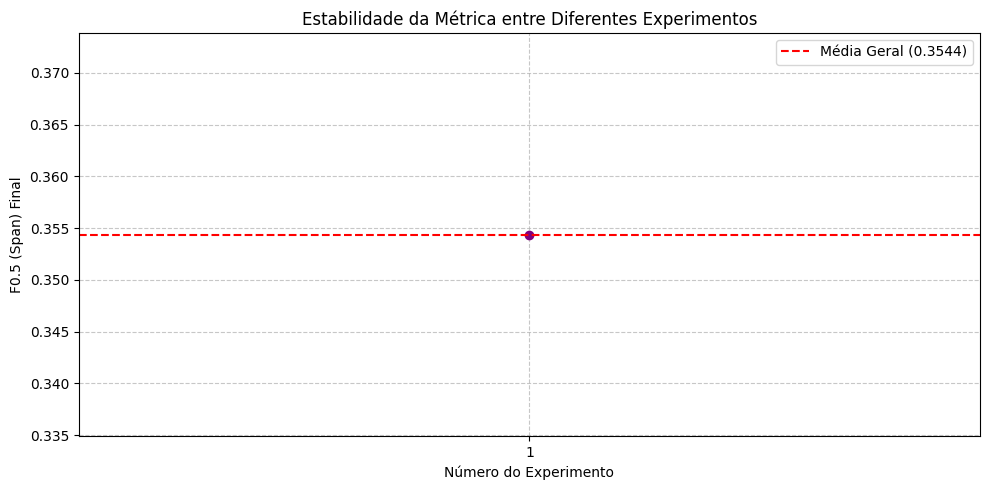

In [37]:
# 1. CURVA DE APRENDIZAGEM E LOSS (Época por Época)
if 'trainer' in locals() and hasattr(trainer, 'state'):
    history = trainer.state.log_history

    train_epocas, train_loss = [], []
    eval_epocas, eval_loss, eval_f05 = [], []

    # Extração segura e independente para evitar erro de dimensão
    for log in history:
        if "loss" in log and "epoch" in log:
            train_epocas.append(log["epoch"])
            train_loss.append(log["loss"])
        if "eval_loss" in log and "epoch" in log:
            eval_epocas.append(log["epoch"])
            eval_loss.append(log["eval_loss"])
            eval_f05.append(log.get("eval_span_f0_5", 0))

    # Plotagem da Curva de Loss e Métrica
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Curvas de Loss (Treino x Validação)
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Loss (Perda)', color='tab:red')
    l1 = ax1.plot(train_epocas, train_loss, color='tab:red', linestyle='--', marker='o', label='Train Loss')
    l2 = ax1.plot(eval_epocas, eval_loss, color='tab:orange', linestyle='-', marker='s', label='Eval Loss')
    ax1.tick_params(axis='y', labelcolor='tab:red')

    # Eixo secundário para a métrica F0.5
    ax2 = ax1.twinx()
    ax2.set_ylabel('F0.5 Span', color='tab:blue')
    l3 = ax2.plot(eval_epocas, eval_f05, color='tab:blue', linestyle='-', marker='^', label='Eval F0.5')
    ax2.tick_params(axis='y', labelcolor='tab:blue')

    # Unifica as legendas dos dois eixos
    lines = l1 + l2 + l3
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')

    plt.title('Curva de Aprendizagem e Perda (Loss) por Época')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("results/curva_aprendizagem_loss.png", dpi=300)
    plt.show()

# 2. ESTABILIDADE ENTRE EXPERIMENTOS
caminho_salvamento_drive = "results/resultados_bertlarge.csv"

if os.path.exists(caminho_salvamento_drive):
    df_resultados = pd.read_csv(caminho_salvamento_drive)
    df_resultados = df_resultados[pd.to_numeric(df_resultados['Precision_token'], errors='coerce').notnull()]
    df_resultados = df_resultados.apply(pd.to_numeric)

    stats_media = df_resultados.mean()
    stats_desvio = df_resultados.std()

    # Cria tabela consolidada sem corromper o CSV base
    df_stats = pd.DataFrame([stats_media, stats_desvio], index=['Média', 'Desvio Padrão'])
    df_final = pd.concat([df_resultados, df_stats])

    # Salva um arquivo de resumo dedicado
    caminho_resumo = "results/resultados_bertlarge_resumo.csv"
    df_final.to_csv(caminho_resumo, index=True)

    print("="*55)
    print(f"📊 RELATÓRIO ESTATÍSTICO GERAL ({len(df_resultados)} EXPERIMENTOS)")
    print("="*55)
    for metrica in df_resultados.columns:
        print(f"{metrica:18}: {stats_media[metrica]:.4f} (± {stats_desvio[metrica]:.4f})")
    print("="*55)
    print(f"\n✅ Relatório completo gravado com sucesso em: '{caminho_resumo}'")

    # Gráfico de estabilidade entre as rodadas
    plt.figure(figsize=(10, 5))
    f0_5_scores = df_resultados['F0.5_span'].values
    rodadas = range(1, len(f0_5_scores) + 1)

    plt.plot(rodadas, f0_5_scores, marker='o', color='purple', linewidth=2)

    media_f0_5 = stats_media['F0.5_span']
    plt.axhline(y=media_f0_5, color='r', linestyle='--', label=f"Média Geral ({media_f0_5:.4f})")

    plt.xlabel('Número do Experimento')
    plt.ylabel('F0.5 (Span) Final')
    plt.title('Estabilidade da Métrica entre Diferentes Experimentos')
    plt.xticks(rodadas)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("results/resumo_todas_rodadas_f05.png", dpi=300)
    plt.show()

else:
    print(f"❌ Erro: O arquivo '{caminho_salvamento_drive}' não foi encontrado no Drive.")